In [3]:
import yfinance as yf
import pandas as pd
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

### Loading the data 

In [4]:
pairs = [
    ("KO", "PEP"),
    ("V", "MA"),
    ("SHEL", "BP"),
]

start = "2016-10-20"
split_date = "2022-10-20"
end = "2026-10-20"  

pair_data = {}

for pair in pairs:
    prices = yf.download(
        list(pair),
        start=start,
        end=end,
        auto_adjust=True,
        progress=False,
    )["Close"].dropna(how="any")

    pair_data[pair] = {
        "train": prices.loc[prices.index < split_date],
        "test": prices.loc[prices.index >= split_date],
    }


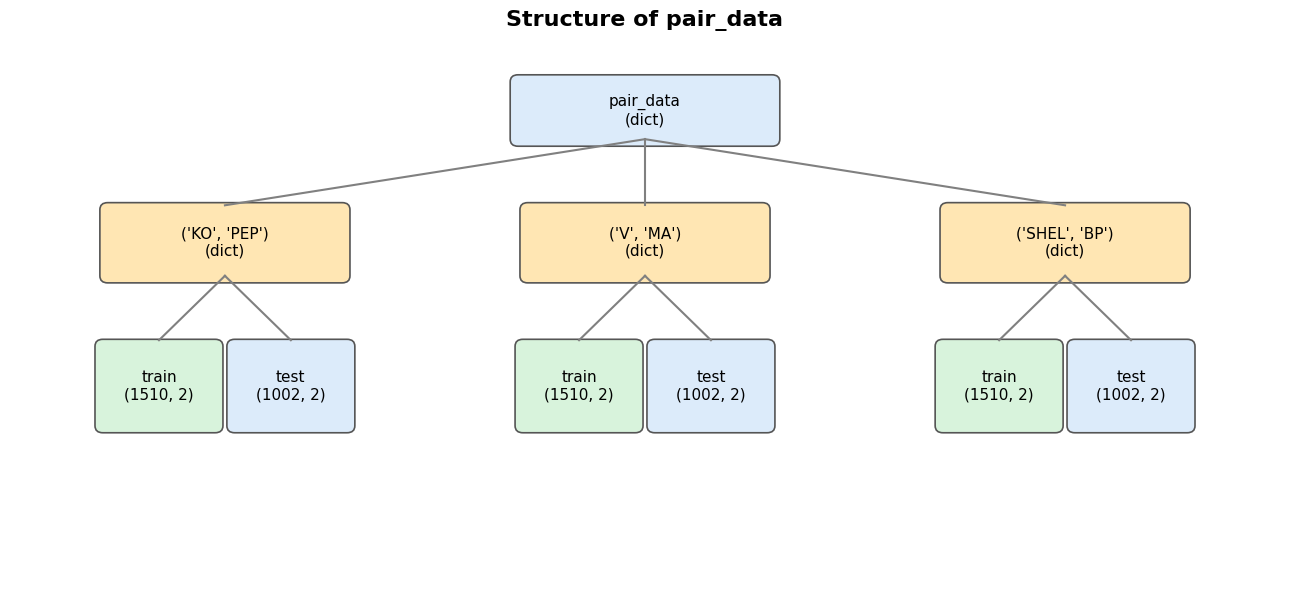

In [5]:
fig, ax = plt.subplots(figsize=(13, 6))
ax.set_xlim(0, 13)
ax.set_ylim(0, 6)
ax.axis("off")

def draw_box(x, y, w, h, text, colour):
    box = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.08",
        facecolor=colour,
        edgecolor="#555555",
        linewidth=1.2
    )
    ax.add_patch(box)
    ax.text(x + w/2, y + h/2, text,
            ha="center", va="center", fontsize=11)

# Outer dictionary
draw_box(5.2, 5, 2.6, 0.65, "pair_data\n(dict)", "#DCEBFA")

# Pair dictionaries
pair_positions = [2.2, 6.5, 10.8]

for pair, x in zip(pairs, pair_positions):
    label = f"{pair}\n(dict)"
    draw_box(x - 1.2, 3.45, 2.4, 0.75, label, "#FFE6B3")

    # Connect root to each pair
    ax.plot([6.5, x], [5, 4.25], color="grey", lw=1.5)

    # Actual training and testing dimensions
    train_shape = pair_data[pair]["train"].shape
    test_shape = pair_data[pair]["test"].shape

    draw_box(x - 1.25, 1.75, 1.15, 0.9,
             f"train\n{train_shape}", "#D8F3DC")
    draw_box(x + 0.1, 1.75, 1.15, 0.9,
             f"test\n{test_shape}", "#DCEBFA")

    # Connect pair to train and test
    ax.plot([x, x - 0.675], [3.45, 2.72], color="grey")
    ax.plot([x, x + 0.675], [3.45, 2.72], color="grey")

ax.set_title("Structure of pair_data", fontsize=16, weight="bold", pad=18)
plt.tight_layout()
plt.show()

### Exploratory data analysis (EDA)

Use the **training data only** to inspect data quality, price movements and stationarity before cointegration testing. Prices are already adjusted for splits and dividends (`auto_adjust=True`). Missing rows were removed during loading, so missing counts below refer only to retained observations.

ADF has a unit-root null: a small p-value supports stationarity. Failure to reject in price levels and rejection in first differences is consistent with I(1), not proof. These tests use an intercept and no deterministic time trend. Correlation alone is not cointegration. All subsequent parameter choices use training observations only.

,Start,End,Observations,Missing,Duplicate dates,Nonpositive prices,Min price,Max price,ADF p (levels),ADF p (differences)
Ticker,,,,,,,,,,
KO,2016-10-20,2022-10-19,1510,0,0,0,29.7118,58.0811,0.6130,0.0
PEP,2016-10-20,2022-10-19,1510,0,0,0,73.1873,156.5329,0.8949,0.0
V,2016-10-20,2022-10-19,1510,0,0,0,70.4377,241.2728,0.4134,0.0
MA,2016-10-20,2022-10-19,1510,0,0,0,94.4906,385.5953,0.4523,0.0
SHEL,2016-10-20,2022-10-19,1510,0,0,0,16.9316,52.1371,0.3591,0.0
BP,2016-10-20,2022-10-19,1510,0,0,0,10.9626,30.3736,0.3046,0.0


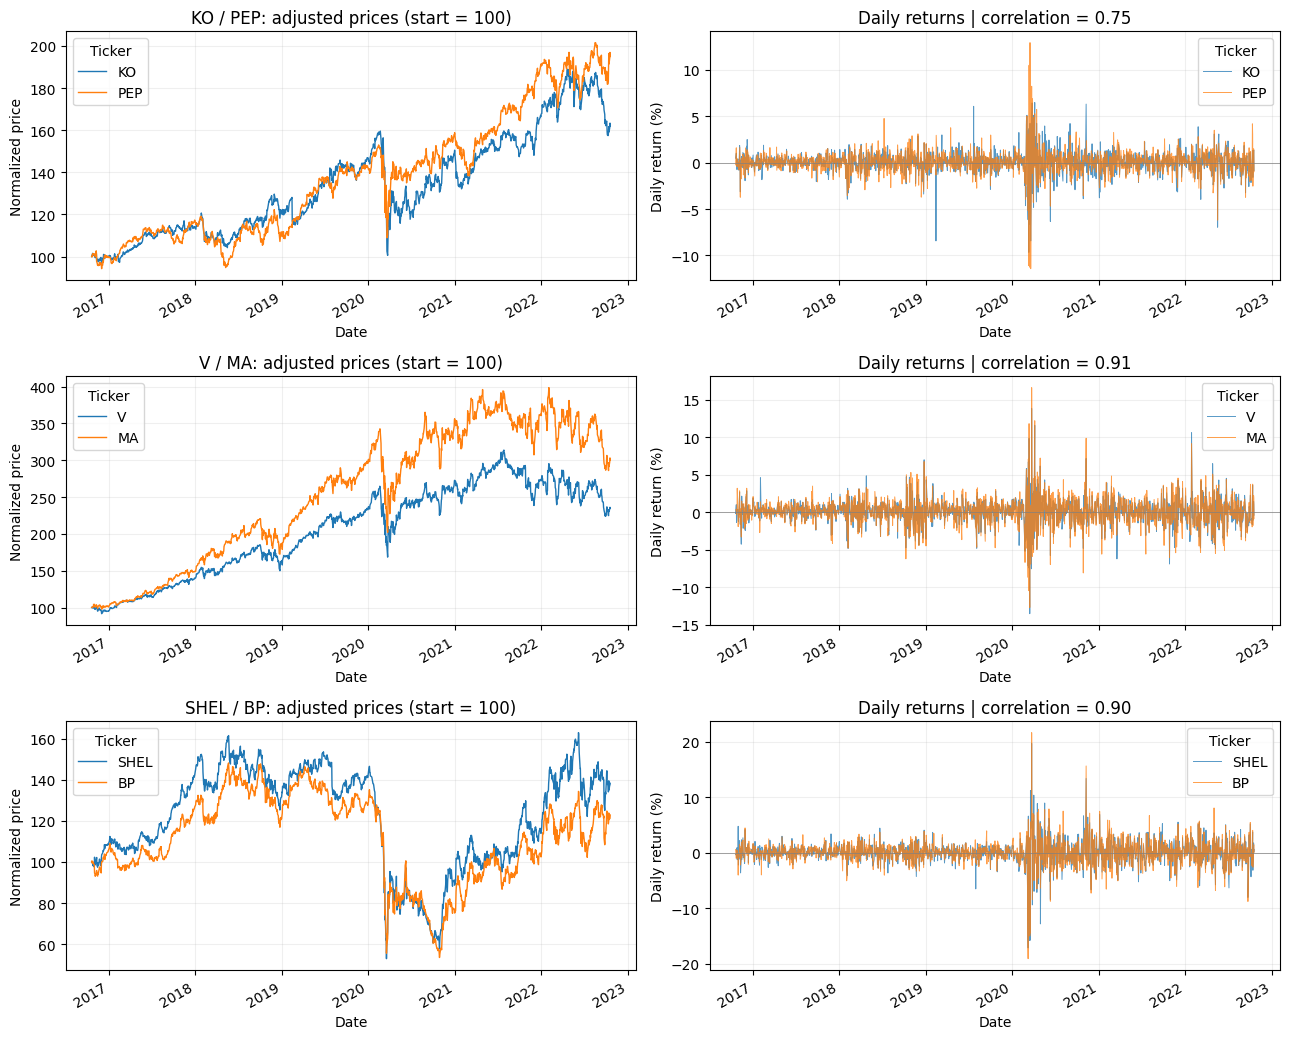

In [6]:
from statsmodels.tsa.stattools import adfuller
from IPython.display import display

# 1. Summarize the retained training data and check integration order.
eda_rows = []
for pair, data in pair_data.items():
    train = data["train"]
    if train.empty:
        raise ValueError(f"No training observations for {pair}")

    for ticker in pair:
        prices = train[ticker]
        eda_rows.append({
            "Ticker": ticker,
            "Start": train.index.min().date(),
            "End": train.index.max().date(),
            "Observations": len(prices),
            "Missing": int(prices.isna().sum()),
            "Duplicate dates": int(train.index.duplicated().sum()),
            "Nonpositive prices": int((prices <= 0).sum()),
            "Min price": prices.min(),
            "Max price": prices.max(),
            "ADF p (levels)": adfuller(prices, regression="c", autolag="AIC")[1],
            "ADF p (differences)": adfuller(prices.diff().dropna(), regression="c", autolag="AIC")[1],
        })

display(pd.DataFrame(eda_rows).set_index("Ticker").round(4))

# 2. Compare price trends and look for large daily moves or volatility changes.
fig, axes = plt.subplots(len(pair_data), 2, figsize=(13, 3.5 * len(pair_data)), squeeze=False)
for row, (pair, data) in enumerate(pair_data.items()):
    train = data["train"].loc[:, list(pair)]
    normalized = train.div(train.iloc[0]).mul(100)
    returns = train.pct_change(fill_method=None).dropna()

    normalized.plot(ax=axes[row, 0], linewidth=1)
    axes[row, 0].set_title(f"{' / '.join(pair)}: adjusted prices (start = 100)")
    axes[row, 0].set_ylabel("Normalized price")

    returns.mul(100).plot(ax=axes[row, 1], linewidth=0.7, alpha=0.75)
    axes[row, 1].set_title(f"Daily returns | correlation = {returns[pair[0]].corr(returns[pair[1]]):.2f}")
    axes[row, 1].set_ylabel("Daily return (%)")
    axes[row, 1].axhline(0, color="grey", linewidth=0.5)
    for ax in axes[row]:
        ax.set_xlabel("Date")
        ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Performing the cointegration test

In [7]:
ols_models = {}
train_spreads = {}
rows = []

for pair, data in pair_data.items():
    train = data["train"]

    y = train[pair[0]]
    x = train[pair[1]]
    ols = sm.OLS(y, sm.add_constant(x)).fit()

    test_stat, p_value, critical_values = coint(
        y, x, trend="c", method="aeg", autolag="aic"
    )

    ols_models[pair] = ols
    train_spreads[pair] = ols.resid.rename("spread")

    rows.append({
        "pair": f"{pair[0]}-{pair[1]}",
        "intercept": ols.params["const"],
        "beta": ols.params[pair[1]],
        "r_squared": ols.rsquared,
        "EG_p_value": p_value,
    })

summary = pd.DataFrame(rows).set_index("pair")
summary = summary.sort_values("EG_p_value")
print(summary)

         intercept      beta  r_squared  EG_p_value
pair                                               
V-MA     27.255233  0.531129   0.990434    0.002855
SHEL-BP  -0.712179  1.736201   0.923375    0.105939
KO-PEP    7.823819  0.310495   0.928917    0.161976


### Training spread diagnostics

These are training-sample Engle–Granger results, not evidence of trading profitability. The reported p-values are unadjusted for testing multiple pairs. We retain the original V-on-MA direction as the baseline and inspect the reverse direction separately, without selecting a direction on test returns.

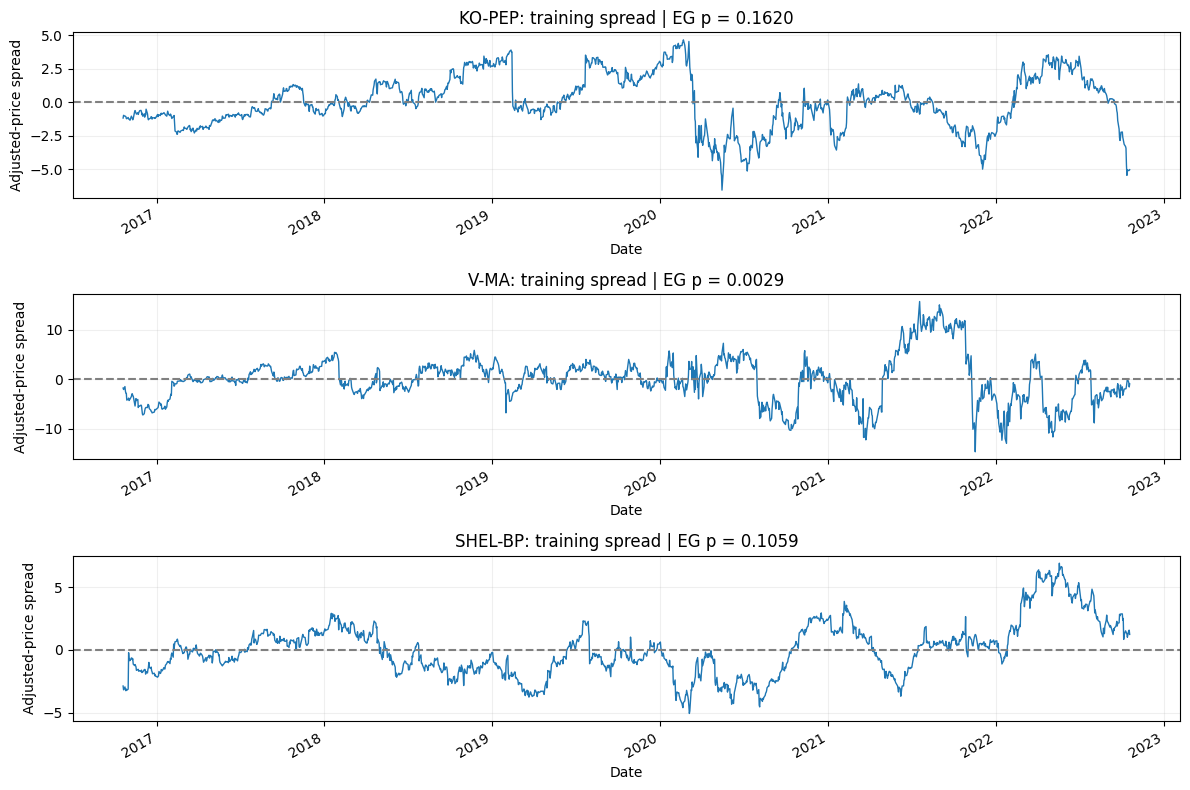

In [8]:
fig, axes = plt.subplots(len(train_spreads), 1, figsize=(12, 8), squeeze=False)
for ax, (pair, spread) in zip(axes[:, 0], train_spreads.items()):
    name = "-".join(pair)
    p_value = summary.loc[name, "EG_p_value"]
    spread.plot(ax=ax, linewidth=1)
    ax.axhline(0, color="grey", linestyle="--")
    ax.set_title(f"{name}: training spread | EG p = {p_value:.4f}")
    ax.set_ylabel("Adjusted-price spread")
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### V–MA: reverse regression and half-life

Chan, Chapter 2, pp. 46–48 (Example 2.4), estimates `change in spread = constant + lambda * lagged spread + error`, with approximate OU half-life `-log(2)/lambda`. We show this alongside the exact AR(1) half-life `-log(2)/log(1 + lambda)`. The half-life belongs to the spread, not the fixed hedge-ratio beta. Neither half-life nor a cointegration p-value guarantees profitable trades.

The initial rolling window is the rounded **training OU half-life**, at least two observations. It is fixed before testing, with no performance optimization. A reverse regression is a diagnostic, not an independent confirmation; its p-value is also unadjusted for multiple testing.

In [9]:
import numpy as np

pair = ("V", "MA")
train_vm = pair_data[pair]["train"].loc[:, list(pair)].copy()
test_vm = pair_data[pair]["test"].loc[:, list(pair)].copy()
if train_vm.empty or test_vm.empty:
    raise ValueError("Both training and test samples are required.")
vm = pd.concat([train_vm, test_vm]).sort_index()
assert vm.index.is_unique and train_vm.index.max() < test_vm.index.min()
assert np.isfinite(vm.to_numpy()).all() and (vm > 0).all().all()

reverse_model = sm.OLS(train_vm["MA"], sm.add_constant(train_vm[["V"]])).fit()
reverse_p = coint(train_vm["MA"], train_vm["V"], trend="c", autolag="aic")[1]
direction_check = pd.DataFrame([
    {"Direction": "V on MA (baseline)", "Beta": ols_models[pair].params["MA"],
     "EG p-value": summary.loc["V-MA", "EG_p_value"]},
    {"Direction": "MA on V (diagnostic)", "Beta": reverse_model.params["V"],
     "EG p-value": reverse_p},
]).set_index("Direction")
display(direction_check.round(6))

v_ma_spread = train_spreads[pair]
hl_data = pd.DataFrame({"change": v_ma_spread.diff(),
                        "lag": v_ma_spread.shift(1)}).dropna()
half_life_model = sm.OLS(hl_data["change"], sm.add_constant(hl_data[["lag"]])).fit()
lambda_ = float(half_life_model.params["lag"])
phi = 1 + lambda_
if not 0 < phi < 1:
    raise ValueError("Training spread does not support a positive, decaying AR(1) half-life.")
v_ma_half_life = -np.log(2) / np.log(phi)
chan_half_life = -np.log(2) / lambda_
lookback = max(2, int(np.floor(chan_half_life + 0.5)))
if lookback >= len(train_vm):
    raise ValueError("Insufficient training data for the half-life-based window.")
print(f"lambda = {lambda_:.5f}; phi = {phi:.5f}")
print(f"Chan OU half-life: {chan_half_life:.2f}; exact AR(1): {v_ma_half_life:.2f} observations")
print(f"Fixed initial lookback: {lookback} trading observations")

,Beta,EG p-value
Direction,,
V on MA (baseline),0.531129,0.002855
MA on V (diagnostic),1.864770,0.003067


lambda = -0.03478; phi = 0.96522
Chan OU half-life: 19.93; exact AR(1): 19.58 observations
Fixed initial lookback: 20 trading observations


### Rolling Z-scores and trading signals

Chan, Chapter 3, pp. 70–72 (Example 3.2): enter long spread below Z = −1, short spread above Z = +1, and exit at/crossing zero. A long spread buys V and sells beta shares of MA for each V share. The intercept enters the signal, not the tradable holdings. Opposite-band jumps can reverse a position.

The baseline uses the training OLS intercept and beta throughout. Rolling mean and standard deviation use data available through each signal date, including that close; trailing training observations warm up the first test signal. Test positions start flat. A signal at close t executes at close t+1 and first earns P&L from t+1 to t+2. This extra delay avoids assuming an already-observed closing price can also be the fill price.

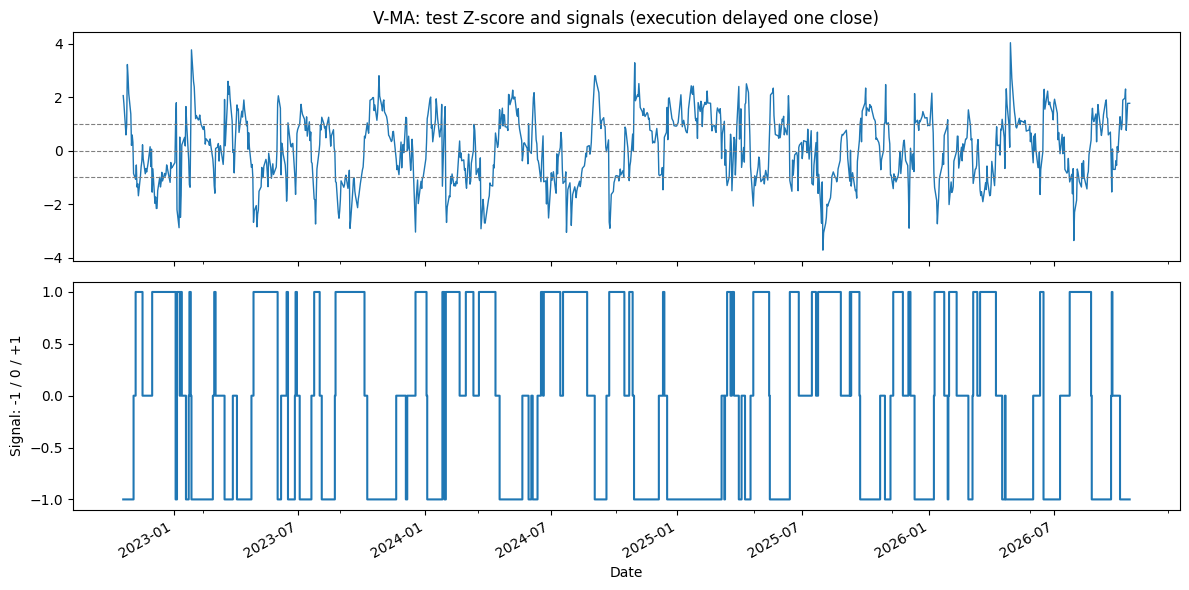

In [10]:
ENTRY_Z = 1.0
COST_BPS = 5.0  # per dollar traded, each leg; includes assumed fees/slippage
BORROW_RATE = 0.02  # assumed annual short-borrow rate, not a measured quote
INITIAL_CAPITAL = 100_000.0
static_alpha = float(ols_models[pair].params["const"])
static_beta = float(ols_models[pair].params["MA"])
static_spread = vm["V"] - static_alpha - static_beta * vm["MA"]
spread_mean = static_spread.rolling(lookback).mean()
spread_std = static_spread.rolling(lookback).std(ddof=1).replace(0, np.nan)
static_z = (static_spread - spread_mean) / spread_std

def positions_from_z(z):
    """State at each signal close; start flat and exit at zero."""
    position = 0
    signals = []
    for value in z:
        if not np.isfinite(value):
            position = 0
        else:
            if (position == 1 and value >= 0) or (position == -1 and value <= 0):
                position = 0
            if position == 0:
                if value < -ENTRY_Z:
                    position = 1
                elif value > ENTRY_Z:
                    position = -1
        signals.append(position)
    return pd.Series(signals, index=z.index, name="signal")

static_signals = positions_from_z(static_z.loc[test_vm.index])
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
static_z.loc[test_vm.index].plot(ax=axes[0], linewidth=1, label="Static OLS Z-score")
for level in [-ENTRY_Z, 0, ENTRY_Z]:
    axes[0].axhline(level, color="grey", linestyle="--", linewidth=0.8)
static_signals.plot(ax=axes[1], drawstyle="steps-post")
axes[0].set_title("V-MA: test Z-score and signals (execution delayed one close)")
axes[1].set_ylabel("Signal: -1 / 0 / +1")
plt.tight_layout()
plt.show()

### Backtest on the reserved test period

This is a daily, self-financing share-accounting simulation: P&L comes from the two held legs, not percentage changes in the spread or changes in beta. At each execution close, holdings are rebalanced to approximately 100% gross exposure relative to current equity; this is a beta hedge, not necessarily dollar-neutral. Cash earns zero and there is no additional leverage. Turnover includes entry, daily resizing/rehedging, exits, reversals and final liquidation. Costs apply to both legs; short borrow accrues over calendar days, including weekends. Sharpe assumes a zero risk-free rate and 252 observations/year.

Adjusted closes approximate total-return leg P&L, including short dividend exposure; actual fills, borrow availability, changing borrow fees, taxes and financing are not modeled. Fractional adjusted-price units are allowed. The loader's end date is exclusive: the actual last available observation is printed below. No stop loss or holding-time optimization is added. This remains a research simulation, and this test set must not subsequently be treated as untouched after examining these results.

In [11]:
def backtest_pair(prices, z, betas, cost_bps=COST_BPS, borrow_rate=BORROW_RATE):
    signals = positions_from_z(z.reindex(prices.index))
    executed = signals.shift(1).fillna(0).astype(int)
    execution_beta = betas.reindex(prices.index).shift(1)
    shares = np.zeros(2)
    equity = INITIAL_CAPITAL
    rows = []
    closes = prices[["V", "MA"]].to_numpy()
    for i, date in enumerate(prices.index):
        previous_equity = equity
        previous_close = closes[i - 1] if i else closes[i]
        pnl = float(shares @ (closes[i] - previous_close))
        days = (date - prices.index[i - 1]).days if i else 0
        borrow = float(np.maximum(-shares * previous_close, 0).sum()) * borrow_rate * days / 365
        equity += pnl - borrow
        if equity <= 0:
            raise ValueError("Equity exhausted; stop the backtest.")
        side = int(executed.iloc[i])
        beta = execution_beta.iloc[i]
        target = np.zeros(2)
        # Liquidate at the final observed close, with closing costs.
        if side and np.isfinite(beta) and i < len(prices) - 1:
            unit = np.array([1.0, -beta])
            # Reserve a small cost buffer when sizing gross exposure.
            target = side * unit * equity / (1 + 2 * cost_bps / 10_000) / (np.abs(unit) @ closes[i])
        traded = float(np.abs(target - shares) @ closes[i])
        cost = traded * cost_bps / 10_000
        equity -= cost
        if equity <= 0:
            raise ValueError("Transaction costs exhausted equity.")
        actual_side = side if np.any(target) else 0
        rows.append({"equity": equity, "return": equity / previous_equity - 1,
                     "pnl": pnl, "transaction_cost": cost, "borrow_cost": borrow,
                     "turnover": traded / previous_equity, "position": actual_side,
                     "gross_exposure": np.abs(target) @ closes[i] / equity})
        shares = target
    result = pd.DataFrame(rows, index=prices.index)
    result["drawdown"] = result["equity"] / result["equity"].cummax().clip(lower=INITIAL_CAPITAL) - 1
    return result

def performance(result):
    r = result["return"]
    previous = result["position"].shift(1).fillna(0)
    entries = (result["position"].ne(0) & result["position"].ne(previous)).sum()
    closed = (previous.ne(0) & result["position"].ne(previous)).sum()
    return pd.Series({
        "Total return": result["equity"].iloc[-1] / INITIAL_CAPITAL - 1,
        "CAGR (252 obs/year)": (result["equity"].iloc[-1] / INITIAL_CAPITAL) ** (252 / len(r)) - 1,
        "Annual volatility": r.std(ddof=1) * np.sqrt(252),
        "Sharpe (rf=0)": r.mean() / r.std(ddof=1) * np.sqrt(252) if r.std(ddof=1) > 0 else np.nan,
        "Max drawdown": result["drawdown"].min(),
        "Entries": entries, "Closed trades": closed,
        "Time invested": result["position"].ne(0).mean(),
        "Transaction costs ($)": result["transaction_cost"].sum(),
        "Borrow costs ($)": result["borrow_cost"].sum(),
    })

static_betas = pd.Series(static_beta, index=vm.index)
baseline = backtest_pair(test_vm, static_z, static_betas)
print(f"Actual test observations: {test_vm.index.min().date()} to {test_vm.index.max().date()} ({len(test_vm)} rows)")
display(performance(baseline).to_frame("Static OLS baseline").round(4))
# Cost scenarios are diagnostics; do not pick parameters using these test results.
cost_sensitivity = pd.DataFrame({
    f"{bps} bps/leg": performance(backtest_pair(test_vm, static_z, static_betas, cost_bps=bps))
    for bps in [0, 5, 10]
})
display(cost_sensitivity.round(4))

Actual test observations: 2022-10-20 to 2026-10-19 (1002 rows)


,Static OLS baseline
Total return,-0.0668
CAGR (252 obs/year),-0.0172
Annual volatility,0.0483
Sharpe (rf=0),-0.3358
Max drawdown,-0.1272
Entries,73.0000
Closed trades,73.0000
Time invested,0.7625
Transaction costs ($),7583.1821
Borrow costs ($),3076.8327


,0 bps/leg,5 bps/leg,10 bps/leg
Total return,0.0069,-0.0668,-0.1351
CAGR (252 obs/year),0.0017,-0.0172,-0.0358
Annual volatility,0.0483,0.0483,0.0485
Sharpe (rf=0),0.0601,-0.3358,-0.7280
Max drawdown,-0.0952,-0.1272,-0.1722
Entries,73.0000,73.0000,73.0000
Closed trades,73.0000,73.0000,73.0000
Time invested,0.7625,0.7625,0.7625
Transaction costs ($),0.0000,7583.1821,14603.0299
Borrow costs ($),3201.1580,3076.8327,2958.7997


### Exploratory comparison: rolling OLS and Kalman hedge ratios

The baseline remains static OLS. Rolling OLS uses the same fixed training half-life window. At each close we apply that day's fitted coefficients to its entire trailing price window before computing the Z-score, avoiding a window that mixes residuals from different hedge ratios.

The Kalman variant follows Chapter 3, pp. 75–80 (Example 3.3): signals use the **prediction error before the state update**, divided by its predicted standard deviation. It is not a rolling Z-score strategy. We initialize coefficients and uncertainty from training OLS and set observation variance from training residual variance. Prices are normalized by their training means; state drift `delta = 0.0001` is a fixed illustrative assumption. This adapts Chan's scale-sensitive setup rather than copying his ETF noise variance to V–MA. No grid search is performed. Coefficients update causally as test observations arrive; both variants retain the same execution delay and accounting as the baseline. Differences reflect both hedge estimation and signal construction, not an isolated beta experiment.

,Static OLS,Rolling OLS (exploratory),Kalman (exploratory)
Total return,-0.0668,-0.1615,0.1444
CAGR (252 obs/year),-0.0172,-0.0433,0.0345
Annual volatility,0.0483,0.0578,0.0422
Sharpe (rf=0),-0.3358,-0.7377,0.8247
Max drawdown,-0.1272,-0.1927,-0.0656
Entries,73.0000,95.0000,25.0000
Closed trades,73.0000,95.0000,25.0000
Time invested,0.7625,0.6856,0.6886
Transaction costs ($),7583.1821,9827.1381,3029.0894
Borrow costs ($),3076.8327,2533.6631,3060.7072


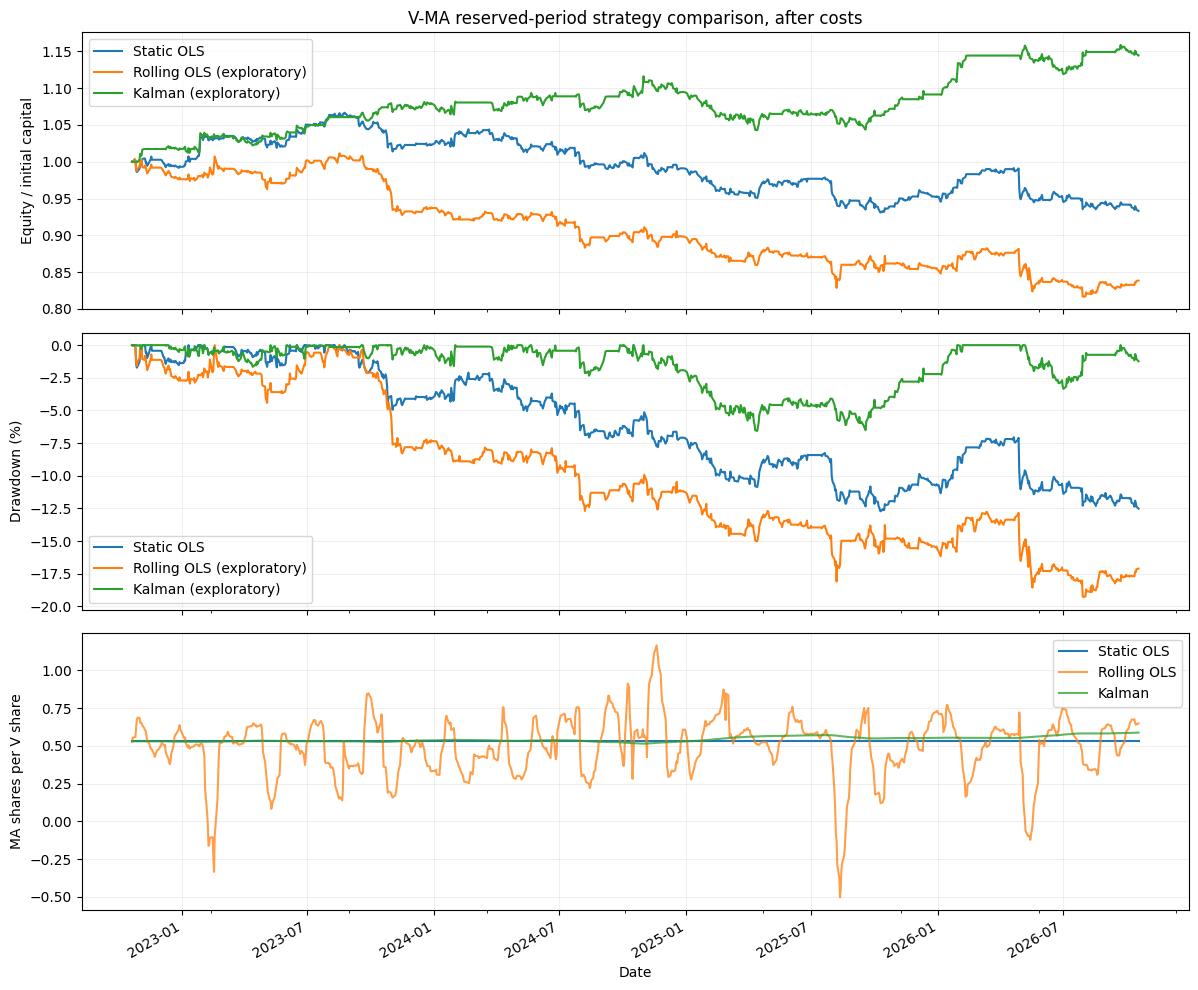

In [12]:
rolling_beta = pd.Series(np.nan, index=vm.index)
rolling_z = pd.Series(np.nan, index=vm.index)
for i in range(lookback - 1, len(vm)):
    window = vm.iloc[i - lookback + 1:i + 1]
    x = window["MA"].to_numpy()
    y = window["V"].to_numpy()
    design = np.column_stack([np.ones(len(x)), x])
    alpha_t, beta_t = np.linalg.lstsq(design, y, rcond=None)[0]
    residuals = y - alpha_t - beta_t * x
    sigma = residuals.std(ddof=1)
    rolling_beta.iloc[i] = beta_t
    if sigma > 0:
        rolling_z.iloc[i] = (residuals[-1] - residuals.mean()) / sigma

scale = train_vm.mean()
normalized_train = train_vm / scale
initial_fit = sm.OLS(normalized_train["V"], sm.add_constant(normalized_train[["MA"]])).fit()
state = initial_fit.params.to_numpy().copy()  # intercept, slope
P = initial_fit.cov_params().to_numpy().copy()
Ve = max(float(initial_fit.mse_resid), 1e-12)
delta = 0.0001
Vw = delta / (1 - delta) * Ve * np.eye(2)
kalman_beta = pd.Series(index=test_vm.index, dtype=float)
kalman_z = pd.Series(index=test_vm.index, dtype=float)
for date, observation in (test_vm / scale).iterrows():
    h = np.array([1.0, observation["MA"]])
    R = P + Vw
    error = observation["V"] - h @ state
    Q = float(h @ R @ h + Ve)
    kalman_z.loc[date] = error / np.sqrt(Q)
    gain = R @ h / Q
    state = state + gain * error
    # Joseph form preserves positive semidefinite covariance numerically.
    update = np.eye(2) - np.outer(gain, h)
    P = update @ R @ update.T + Ve * np.outer(gain, gain)
    kalman_beta.loc[date] = state[1] * scale["V"] / scale["MA"]

results = {
    "Static OLS": baseline,
    "Rolling OLS (exploratory)": backtest_pair(test_vm, rolling_z, rolling_beta),
    "Kalman (exploratory)": backtest_pair(test_vm, kalman_z, kalman_beta),
}
comparison = pd.DataFrame({name: performance(result) for name, result in results.items()})
display(comparison.round(4))

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for name, result in results.items():
    (result["equity"] / INITIAL_CAPITAL).plot(ax=axes[0], label=name)
    result["drawdown"].mul(100).plot(ax=axes[1], label=name)
static_betas.loc[test_vm.index].plot(ax=axes[2], label="Static OLS")
rolling_beta.loc[test_vm.index].plot(ax=axes[2], label="Rolling OLS", alpha=0.75)
kalman_beta.plot(ax=axes[2], label="Kalman", alpha=0.75)
axes[0].set_title("V-MA reserved-period strategy comparison, after costs")
axes[0].set_ylabel("Equity / initial capital")
axes[1].set_ylabel("Drawdown (%)")
axes[2].set_ylabel("MA shares per V share")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Findings from this execution

The available test sample runs from **20 October 2022 to 19 October 2026** (1,002 observations). Forward and reverse training cointegration p-values are approximately **0.002855** and **0.003067**. The OU half-life is **19.93** observations (exact AR(1): **19.58**), giving a fixed **20-observation** window.

| Model | Net total return | Annualized return | Sharpe (rf = 0) | Maximum drawdown | Closed trades |
|---|---:|---:|---:|---:|---:|
| Static OLS baseline | ?6.68% | ?1.72% | ?0.34 | ?12.72% | 73 |
| Rolling OLS, exploratory | ?16.15% | ?4.33% | ?0.74 | ?19.27% | 95 |
| Kalman, exploratory | +14.44% | +3.45% | 0.82 | ?6.56% | 25 |

These are simulated results at **5 bps per leg traded** and **2% annual short borrow**, not live results. Static OLS paid about **$7,583 in transaction costs** plus **$3,077 in borrow costs** on $100,000 initial capital. Removing transaction costs, while retaining borrow, raises its total return to only **+0.69%**; at 10 bps per leg it returns **?13.51%**. The baseline is therefore not supported as a profitable strategy under these assumptions, despite significant training cointegration.

Rolling OLS did not improve the result and generated more trades. Its short-window beta occasionally becomes negative, which produces same-direction leg exposures rather than the intended opposing-leg hedge; this is an additional sign of instability. No beta-sign filter was retrofitted after seeing test results. Kalman looks more promising in this particular sample, with fewer trades and lower drawdown, but only 25 completed trades and a different innovation-based signal. It has not established robustness or isolated the benefit of a dynamic hedge ratio. Keep these parameters fixed and assess a fresh period or a prespecified walk-forward design before drawing a stronger conclusion. Do not optimize on this already-inspected test sample.

This is an execution snapshot; rerunning with revised Yahoo data or different assumptions can change the numbers. The computed tables above are authoritative for the latest execution.

### Reading the results

Assess the static baseline first: net return, drawdown, number of completed trades and sensitivity to costs matter alongside Sharpe. Cointegration is a historical relationship, not a promise that the spread remains stable out of sample. The training pair selection and extra reverse-direction test introduce selection uncertainty; ordinary daily Sharpe also ignores serial dependence and has no confidence interval here.

Treat rolling and Kalman results as exploratory evidence. Comparing them has now used the reserved period; choosing the best performer would require another genuinely unseen period or a prespecified walk-forward evaluation. No thresholds, lookbacks or Kalman parameters were optimized. Before deployment, investigate execution prices, short availability, realistic broker fees, stability over subperiods and a separate validation period.

Book references: Ernest P. Chan (2013), *Algorithmic Trading: Winning Strategies and Their Rationale*, Chapter 2, pp. 46–48 (half-life), and Chapter 3, pp. 70–80 (Bollinger bands and Kalman filtering). These refer to printed page numbers in the supplied PDF, not PDF viewer indices.